# Object Detection on Real Driving Images: from IoU to Per-Class AP on KITTI

**Module 01 · Perception and Prediction** · Notebook 4 of 9

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/01_Perception/04_object_detection.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [02 Sensor modalities](02_sensor_modalities.ipynb); [03 LiDAR and point clouds](03_lidar_point_clouds.ipynb); basic Python/NumPy | ISO 21448:2022; ISO/PAS 8800:2024 |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Describe what a 2D object detector outputs and how one-stage, two-stage and transformer detectors differ
2. Run a pretrained detector on real KITTI images and compare its output with the ground truth
3. Implement IoU, non-maximum suppression (NMS), precision–recall and Average Precision from scratch, and check them against reference implementations
4. Evaluate a detector the KITTI way: per class, per difficulty, with class-specific IoU thresholds and ignore rules — and explain the pitfalls of mapping COCO classes to KITTI classes
5. Analyse real failure cases (missed objects, false positives) and relate them to triggering conditions
6. Define a detection KPI precisely enough for it to be used as SOTIF evidence

## Setup

The notebook runs on CPU. It uses the **torchvision** Faster R-CNN with a MobileNetV3-Large FPN backbone, pretrained on COCO (about 75 MB of weights, downloaded once). Each KITTI image is read directly from the official archive (about 1–2 s per image, then cached), and the detector's raw output for each frame is cached as well, so a second run is fast. [Ultralytics YOLO](https://docs.ultralytics.com/) is optional and used only if it is installed (e.g. on Colab).

In [1]:
# Course toolkit (tables, formulas and real-data loaders). Installs automatically on Colab.
try:
    import avsafety
except ImportError:
    %pip install -q "avsafety[data] @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    import avsafety
from avsafety import data as D

In [2]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display
import torch, torchvision
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_fpn

torch.set_num_threads(1)          # one thread is the most robust choice on shared CPUs (Colab, CI); raise it on a dedicated machine
rng = np.random.default_rng(42)
OKABE_ITO = ['#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7', '#000000']
CLS_COL = {'Car': OKABE_ITO[4], 'Pedestrian': OKABE_ITO[5], 'Cyclist': OKABE_ITO[2]}
plt.rcParams.update({'figure.dpi': 100})
print(f"torch {torch.__version__}, torchvision {torchvision.__version__}, CPU threads used: {torch.get_num_threads()}")

torch 2.15.0+cpu, torchvision 0.29.2+cpu, CPU threads used: 1


### Data and licence

Images and labels come from the **KITTI object-detection training set** (7,481 images from Karlsruhe, 1242 × 375 px). Licence: CC BY-NC-SA 3.0, non-commercial — results may be published, but a model tuned on KITTI must not be used in a product (see [08 Driving datasets](08_driving_datasets.ipynb)).

In [3]:
print(D.attribution('KITTI'))
labels_all = D.kitti_object_labels_all()

# Reproducible, stratified frame selection: 12 frames with an evaluable pedestrian, 12 with an evaluable
# cyclist, 12 others. Recomputed here and checked against the stored list.
ev = labels_all[labels_all['difficulty'] != 'Ignored']
sel_rng = np.random.default_rng(2026)
ped_f = sorted(ev.loc[ev['type'] == 'Pedestrian', 'frame'].astype(int).unique())
cyc_f = sorted(ev.loc[ev['type'] == 'Cyclist', 'frame'].astype(int).unique())
chosen = set(sel_rng.choice(ped_f, 12, replace=False).tolist())
chosen |= set(sel_rng.choice([f for f in cyc_f if f not in chosen], 12, replace=False).tolist())
chosen |= set(sel_rng.choice([f for f in range(7481) if f not in chosen], 12, replace=False).tolist())
FRAMES = [95, 193, 564, 804, 1234, 1355, 1460, 2007, 2439, 2666, 2715, 2727, 2739, 3254, 3287, 3343, 3390, 3398,
          3480, 3570, 3686, 4364, 4447, 4515, 4613, 4737, 4753, 4790, 5495, 5878, 6010, 6176, 6204, 6277, 6690, 7404]
assert sorted(chosen) == FRAMES, "frame selection changed"

gt_sel = labels_all[labels_all['frame'].astype(int).isin(FRAMES)]
print(f"{len(FRAMES)} frames, {len(gt_sel)} label lines")
display(pd.crosstab(gt_sel['type'], gt_sel['difficulty'])[['Easy', 'Moderate', 'Hard', 'Ignored']])

Data: KITTI Vision Benchmark Suite (Geiger et al., CVPR 2012 / IJRR 2013), CC BY-NC-SA 3.0, https://www.cvlibs.net/datasets/kitti/


36 frames, 294 label lines


difficulty,Easy,Moderate,Hard,Ignored
type,,,,
Car,33,48,14,24
Cyclist,13,9,2,1
DontCare,14,13,0,37
Misc,2,0,1,0
Pedestrian,34,24,7,4
Person_sitting,2,0,0,1
Tram,0,1,0,0
Truck,0,1,1,0
Van,1,3,3,1


---
## 1. What is object detection?

**Input:** an image (here 1242 × 375 pixels, 3 colour channels). **Output:** a list of objects, each with

- a **bounding box** — `[x1, y1, x2, y2]` (corner format, used here and by KITTI) or `[x, y, w, h]` (COCO format);
- a **class label** — "car", "person", "bicycle", …;
- a **confidence score** in [0, 1] — a ranking score, *not* a calibrated probability.

### Architecture families
- **Two-stage** (R-CNN family, e.g. Faster R-CNN): a region proposal network, then classification and box refinement per proposal. Used in this notebook (with a light MobileNetV3 backbone and a feature pyramid network, FPN, for CPU speed).
- **One-stage** (SSD, RetinaNet, YOLO family): dense prediction in a single pass; real-time on GPUs.
- **Transformer-based** (DETR, RT-DETR): set prediction without hand-designed anchors and without NMS.

**YOLO versions (as of October 2026):** YOLOv8 (2023) is a well-documented baseline; YOLO11 (2024) and YOLO26 (January 2026, end-to-end **NMS-free**) are the current Ultralytics models ([Ultralytics docs](https://docs.ultralytics.com/compare/yolo26-vs-yolo11)). Frame rates are hardware-dependent — always measure on the target.

### The KITTI ground truth
Each KITTI label line contains the class, **truncation** (0–1, share of the object outside the image), **occlusion** (0 fully visible, 1 partly occluded, 2 largely occluded, 3 unknown), the 2D box, and the 3D size, position and heading. KITTI evaluates **Car, Pedestrian and Cyclist** on three **difficulty levels**:

| Level | Min. box height | Max. occlusion | Max. truncation |
|---|---|---|---|
| Easy | 40 px | 0 (fully visible) | 15 % |
| Moderate | 25 px | 1 (partly occluded) | 30 % |
| Hard | 25 px | 2 (largely occluded) | 50 % |

The levels are cumulative: *Moderate* includes all Easy objects. The official ranking uses Moderate. Objects outside all three levels, and the `DontCare` regions, are **ignored**: detecting them is neither rewarded nor penalised.

---
## 2. COCO classes are not KITTI classes

The detector was trained on **COCO** (80 everyday classes); KITTI uses its own 8 classes. Any evaluation of a COCO model on KITTI therefore needs a **class mapping**, and every mapping is a design decision with consequences:

| KITTI class | COCO source used here | Pitfall |
|---|---|---|
| Car | `car` | COCO `car` also fires on KITTI **Vans** (minibuses, delivery vans), and COCO `truck` fires on some KITTI Cars. KITTI treats Van as a *neighbouring* class for Car: a car detection on a van is ignored, not a false positive. |
| Pedestrian | `person` | COCO `person` also covers **Person_sitting** (ignored by KITTI for Pedestrian) and the **rider** of a bicycle, which KITTI labels as Cyclist — a rider detected as `person` becomes a pedestrian false positive. |
| Cyclist | `person` + `bicycle`, merged | KITTI's Cyclist box encloses rider **and** bicycle; COCO detects them separately. We merge a `person` box with an overlapping `bicycle` box below it; parked bicycles without a rider are dropped. |
| — | `truck`, `bus`, `motorcycle` | Not mapped: KITTI Truck/Tram/Misc are not evaluated. |
| DontCare | — | Unlabelled regions (distant cars, crowds). A detection inside one is ignored, otherwise every correct detection of an unlabelled object would count as a false positive. |

The mapping is applied *after* the detector, so the numbers below measure a COCO model that has **never seen KITTI** — a realistic picture of how a model behaves outside its training distribution, not the state of the art on KITTI.

In [4]:
MODEL_NAME = 'fasterrcnn_mobilenet_v3_large_fpn'
COCO_NAMES = {1: 'person', 2: 'bicycle', 3: 'car', 4: 'motorcycle', 6: 'bus', 8: 'truck'}
DET_DIR = D.cache_dir() / 'detections' / f"{MODEL_NAME}_tv{torchvision.__version__.split('+')[0]}"
_model = None

def get_model():
    global _model
    if _model is None:
        _model = fasterrcnn_mobilenet_v3_large_fpn(weights='DEFAULT').eval()   # COCO weights, ~75 MB once
    return _model

def detect(index, image=None):
    # Raw COCO detections (score >= 0.05) for KITTI training frame `index`, cached on disk after the first run.
    path = DET_DIR / f'{index:06d}.npz'
    if path.exists():
        with np.load(path) as z:
            return {k: z[k] for k in z.files}
    if image is None:
        image = D.kitti_object(index, parts=('image',)).image
    x = torch.from_numpy(image.copy()).permute(2, 0, 1).float() / 255
    t0 = time.perf_counter()
    with torch.no_grad():
        out = get_model()([x])[0]
    res = {'boxes': out['boxes'].numpy(), 'labels': out['labels'].numpy(), 'scores': out['scores'].numpy(),
           'latency_ms': np.array(1000 * (time.perf_counter() - t0))}
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.stem + f'.{os.getpid()}.tmp.npz')
    np.savez(tmp, **res); os.replace(tmp, path)
    return res

def to_kitti(raw):
    # Map COCO detections of one frame to KITTI classes (see the table above).
    names = [COCO_NAMES.get(int(c)) for c in raw['labels']]
    boxes, scores = raw['boxes'], raw['scores']
    persons = [i for i, n in enumerate(names) if n == 'person']
    bikes = sorted((i for i, n in enumerate(names) if n == 'bicycle'), key=lambda i: -scores[i])
    used, out = set(), []
    for b in bikes:                                   # rider = person overlapping the bicycle horizontally, above it
        bx, best = boxes[b], None
        for p in persons:
            px = boxes[p]
            overlap_x = max(0.0, min(px[2], bx[2]) - max(px[0], bx[0])) / max(px[2] - px[0], 1e-6)
            if p not in used and overlap_x >= 0.5 and px[1] < bx[1] < px[3] and (best is None or scores[p] > scores[best]):
                best = p
        if best is not None:
            used.add(best); px = boxes[best]
            out.append({'cls': 'Cyclist', 'score': float(np.sqrt(scores[b] * scores[best])), 'coco': 'person+bicycle',
                        'box': np.array([min(px[0], bx[0]), min(px[1], bx[1]), max(px[2], bx[2]), max(px[3], bx[3])])})
    for i, n in enumerate(names):
        if n == 'car':
            out.append({'cls': 'Car', 'score': float(scores[i]), 'box': boxes[i], 'coco': n})
        elif n == 'person' and i not in used:
            out.append({'cls': 'Pedestrian', 'score': float(scores[i]), 'box': boxes[i], 'coco': n})
    return out

frames, raw_dets, t_start = {}, {}, time.perf_counter()
for idx in FRAMES:
    try:
        frames[idx] = D.kitti_object(idx, parts=('image', 'labels'))
    except D.DataUnavailable as exc:
        raise SystemExit(f"KITTI not reachable ({exc}). This notebook needs network access once; then it runs from cache.")
    for l in frames[idx].labels:
        l['difficulty'] = D.kitti_difficulty(l)
    raw_dets[idx] = detect(idx, frames[idx].image)
dets = {idx: to_kitti(r) for idx, r in raw_dets.items()}
n_raw = sum(len(r['scores']) for r in raw_dets.values())
print(f"Detector: {MODEL_NAME} (COCO weights); {len(FRAMES)} frames processed in {time.perf_counter() - t_start:.0f} s "
      f"(including any downloads; cached afterwards)")
print(f"{n_raw} raw detections with score >= 0.05 -> {sum(map(len, dets.values()))} after mapping to KITTI classes")

Detector: fasterrcnn_mobilenet_v3_large_fpn (COCO weights); 36 frames processed in 1 s (including any downloads; cached afterwards)
1860 raw detections with score >= 0.05 -> 1084 after mapping to KITTI classes


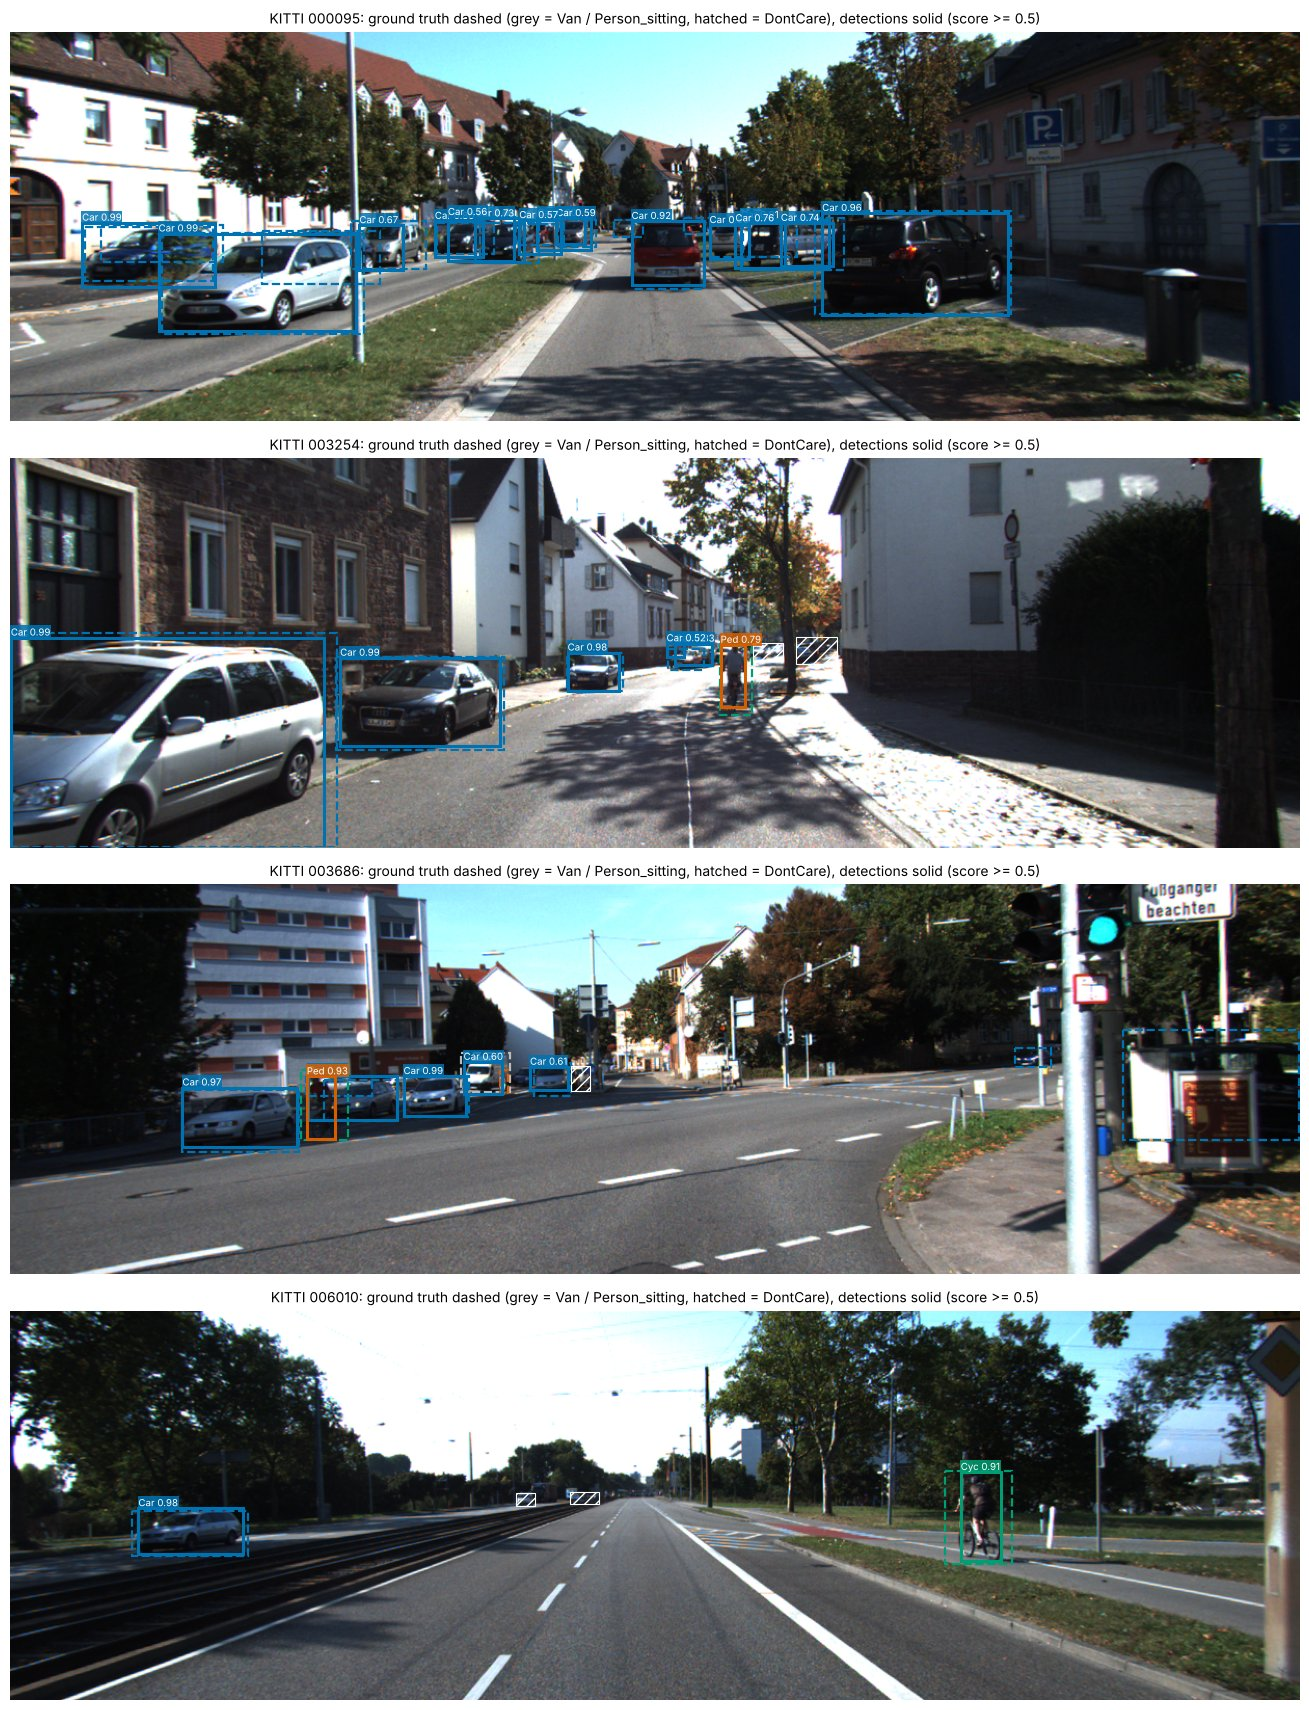

  000095: 15 Car/Pedestrian/Cyclist labels, 15 detections with score >= 0.5
  003254: 5 Car/Pedestrian/Cyclist labels, 6 detections with score >= 0.5
  003686: 9 Car/Pedestrian/Cyclist labels, 6 detections with score >= 0.5
  006010: 2 Car/Pedestrian/Cyclist labels, 2 detections with score >= 0.5


In [5]:
OP_THR = 0.5                                       # operating confidence threshold used for the pictures

def draw_frame(ax, idx, thr=OP_THR, title=None):
    fr = frames[idx]; ax.imshow(fr.image); ax.axis('off')
    for l in fr.labels:
        x1, y1, x2, y2 = l['x1'], l['y1'], l['x2'], l['y2']
        if l['type'] == 'DontCare':
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, hatch='///', lw=0.8, edgecolor='white'))
        elif l['type'] in CLS_COL or l['type'] in ('Van', 'Person_sitting'):
            col = CLS_COL.get(l['type'], '#BBBBBB')
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.6, ls='--', edgecolor=col))
    for d in dets[idx]:
        if d['score'] >= thr:
            x1, y1, x2, y2 = d['box']
            ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=2.2, edgecolor=CLS_COL[d['cls']]))
            ax.text(x1, y1 - 2, f"{d['cls'][:3]} {d['score']:.2f}", color='white', fontsize=7,
                    bbox=dict(facecolor=CLS_COL[d['cls']], alpha=0.85, pad=0.5, edgecolor='none'))
    ax.set_title(title or f"KITTI {idx:06d}", fontsize=10)

show = [FRAMES[0], FRAMES[13], FRAMES[20], FRAMES[30]]
fig, axes = plt.subplots(len(show), 1, figsize=(14, 4.3 * len(show)))
for ax, idx in zip(axes, show):
    draw_frame(ax, idx, title=f"KITTI {idx:06d}: ground truth dashed (grey = Van / Person_sitting, hatched = DontCare), "
                              f"detections solid (score >= {OP_THR})")
plt.tight_layout(); plt.show()
for idx in show:
    n_gt = sum(l['type'] in CLS_COL for l in frames[idx].labels)
    n_det = sum(d['score'] >= OP_THR for d in dets[idx])
    print(f"  {idx:06d}: {n_gt} Car/Pedestrian/Cyclist labels, {n_det} detections with score >= {OP_THR}")

**What the mapping does in practice.** The cell below takes every detection with score ≥ 0.5, finds the ground-truth label it overlaps best (IoU ≥ 0.5), and tabulates COCO class against KITTI class. Off-diagonal entries are the ontology mismatches from the table above, measured on real data.

In [6]:
def iou_matrix(A, B):
    # Vectorised IoU between every box in A (N,4) and B (M,4), [x1, y1, x2, y2].
    A, B = np.asarray(A, float).reshape(-1, 4), np.asarray(B, float).reshape(-1, 4)
    ix1 = np.maximum(A[:, None, 0], B[None, :, 0]); iy1 = np.maximum(A[:, None, 1], B[None, :, 1])
    ix2 = np.minimum(A[:, None, 2], B[None, :, 2]); iy2 = np.minimum(A[:, None, 3], B[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    area = lambda X: (X[:, 2] - X[:, 0]) * (X[:, 3] - X[:, 1])
    union = area(A)[:, None] + area(B)[None, :] - inter
    return np.where(union > 0, inter / np.maximum(union, 1e-12), 0.0)

rows = []
for idx in FRAMES:
    r = raw_dets[idx]; labs = [l for l in frames[idx].labels if l['type'] != 'DontCare']
    keep = (r['scores'] >= 0.5) & np.isin(r['labels'], list(COCO_NAMES))
    if not keep.any():
        continue
    gb = np.array([[l['x1'], l['y1'], l['x2'], l['y2']] for l in labs]).reshape(-1, 4)
    ov = iou_matrix(r['boxes'][keep], gb) if len(labs) else np.zeros((keep.sum(), 0))
    for c, o in zip(r['labels'][keep], ov):
        best = labs[int(np.argmax(o))]['type'] if len(o) and o.max() >= 0.5 else 'no label (IoU < 0.5)'
        rows.append({'COCO class': COCO_NAMES[int(c)], 'best KITTI label': best})
xtab = pd.crosstab(pd.DataFrame(rows)['COCO class'], pd.DataFrame(rows)['best KITTI label'])
display(xtab)
for (cc, kc) in [('car', 'Van'), ('truck', 'Car'), ('person', 'Cyclist'), ('person', 'Person_sitting'), ('bicycle', 'Cyclist')]:
    n = int(xtab.loc[cc, kc]) if cc in xtab.index and kc in xtab.columns else 0
    print(f"  COCO '{cc}' on KITTI '{kc}': {n}")
nb_free = int(xtab.loc['bicycle', 'no label (IoU < 0.5)']) if 'bicycle' in xtab.index else 0
print(f"  COCO 'bicycle' overlapping no label: {nb_free} (mostly parked bicycles, which KITTI does not label)")
print("Without the merge, every correctly found cyclist rider would be scored as a pedestrian false positive.")

best KITTI label,Car,Cyclist,Misc,Pedestrian,Person_sitting,Van,no label (IoU < 0.5)
COCO class,,,,,,,
bicycle,0,0,0,0,0,0,43
bus,0,0,0,0,0,2,2
car,96,0,0,0,0,3,32
motorcycle,0,1,0,0,0,0,3
person,0,9,0,40,1,0,36
truck,2,0,3,0,0,1,0


  COCO 'car' on KITTI 'Van': 3
  COCO 'truck' on KITTI 'Car': 2
  COCO 'person' on KITTI 'Cyclist': 9
  COCO 'person' on KITTI 'Person_sitting': 1
  COCO 'bicycle' on KITTI 'Cyclist': 0
  COCO 'bicycle' overlapping no label: 43 (mostly parked bicycles, which KITTI does not label)
Without the merge, every correctly found cyclist rider would be scored as a pedestrian false positive.


---
## 3. Intersection over Union (IoU)

IoU measures how well two boxes overlap:

$$ \mathrm{IoU}(A, B) = \frac{|A \cap B|}{|A \cup B|} = \frac{|A \cap B|}{|A| + |B| - |A \cap B|} $$

It is used (i) to decide whether a detection matches a ground-truth object and (ii) inside NMS to decide whether two detections are duplicates. KITTI requires IoU ≥ **0.7 for cars** and ≥ **0.5 for pedestrians and cyclists**.

Pedestrian: a 26 px wide box still matches at IoU >= 0.5 for horizontal shifts up to 8.5 px (33 % of its width)
Car: a 69 px wide box still matches at IoU >= 0.7 for horizontal shifts up to 12.0 px (17 % of its width)


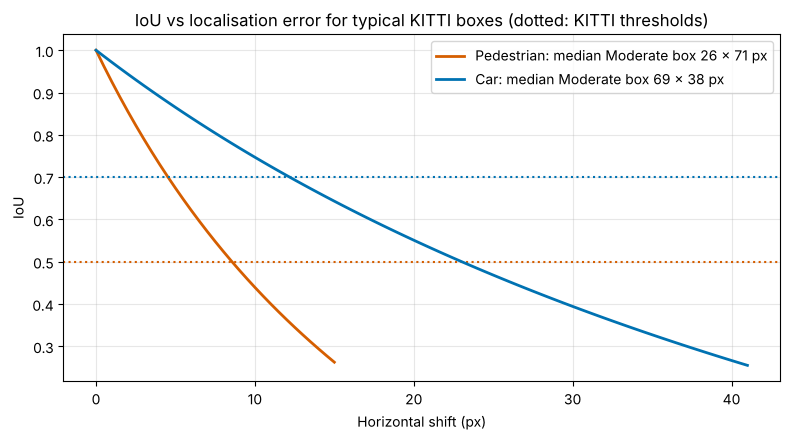

IoU checks passed (hand values and torchvision.ops.box_iou). A small pedestrian tolerates only a few pixels of error.


In [7]:
def iou(a, b):
    # IoU of two boxes in [x1, y1, x2, y2] format.
    ix1, iy1 = max(a[0], b[0]), max(a[1], b[1])
    ix2, iy2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, ix2 - ix1) * max(0.0, iy2 - iy1)
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0

# Sanity checks with hand-computed values, and against torchvision's reference implementation
assert iou([0, 0, 10, 10], [0, 0, 10, 10]) == 1.0
assert iou([0, 0, 10, 10], [20, 20, 30, 30]) == 0.0
assert abs(iou([0, 0, 10, 10], [5, 0, 15, 10]) - 50 / 150) < 1e-12     # half overlap -> 1/3
assert np.allclose(iou_matrix([[0, 0, 10, 10]], [[5, 0, 15, 10], [0, 0, 10, 10]]), [[1/3, 1.0]])
some = np.concatenate([raw_dets[i]['boxes'][:20] for i in FRAMES[:5]])
assert np.allclose(iou_matrix(some, some), torchvision.ops.box_iou(torch.tensor(some), torch.tensor(some)).numpy(), atol=1e-5)

# How fast IoU drops when a box is shifted, for the median real KITTI pedestrian and car box
med = {c: labels_all.loc[(labels_all['type'] == c) & (labels_all['difficulty'] == 'Moderate')]
                  .eval('w_px = x2 - x1').eval('h_px = y2 - y1')[['w_px', 'h_px']].median() for c in ['Pedestrian', 'Car']}
fig, ax = plt.subplots(figsize=(8, 4.5))
for c, thr in [('Pedestrian', 0.5), ('Car', 0.7)]:
    w, h = med[c]; box = [0, 0, w, h]
    shifts = np.arange(0, 0.6 * w, 0.5)
    ious = [iou(box, [s, 0, w + s, h]) for s in shifts]
    ax.plot(shifts, ious, color=CLS_COL[c], lw=2, label=f"{c}: median Moderate box {w:.0f} x {h:.0f} px")
    lim = shifts[np.array(ious) >= thr].max()
    ax.axhline(thr, color=CLS_COL[c], ls=':')
    print(f"{c}: a {w:.0f} px wide box still matches at IoU >= {thr} for horizontal shifts up to {lim:.1f} px "
          f"({100 * lim / w:.0f} % of its width)")
ax.set_xlabel('Horizontal shift (px)'); ax.set_ylabel('IoU'); ax.legend(); ax.grid(alpha=0.3)
ax.set_title('IoU vs localisation error for typical KITTI boxes (dotted: KITTI thresholds)')
plt.tight_layout(); plt.show()
print("IoU checks passed (hand values and torchvision.ops.box_iou). A small pedestrian tolerates only a few pixels of error.")

---
## 4. Non-Maximum Suppression (NMS)

A detector proposes many overlapping boxes for the same object. **Greedy NMS** keeps the highest-scoring box, removes every remaining box of the same class whose IoU with it exceeds a threshold, and repeats. (YOLO26 and DETR-style detectors are trained to output one box per object and need no NMS.)

To see real pre-NMS output, we run the detector once more on one frame with its internal NMS switched off (IoU threshold 1.0) and apply our own NMS.

Our NMS matches torchvision.ops.batched_nms: True


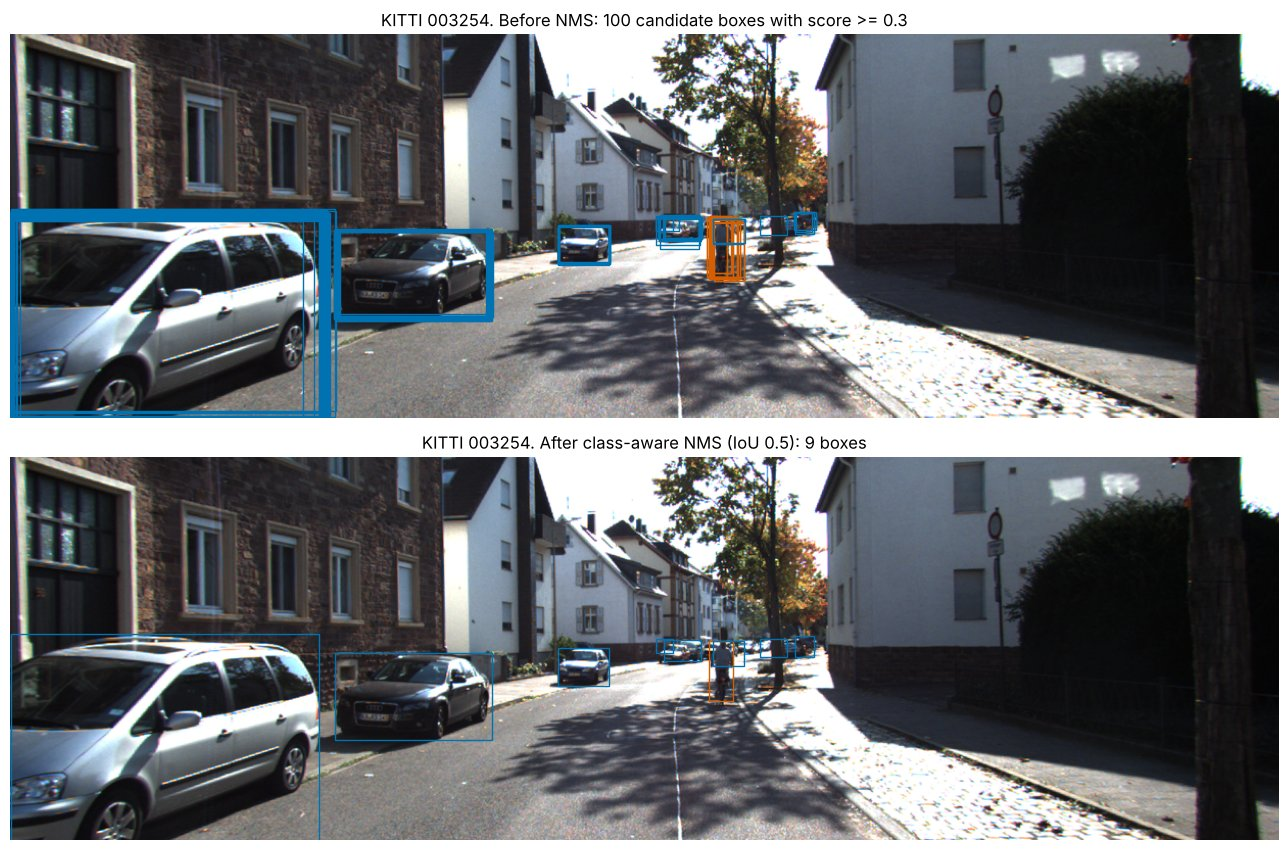

NMS reduced 100 candidates to 9 boxes.


In all 7,481 KITTI frames, 265 pairs of labelled pedestrians/cyclists overlap with IoU > 0.5: a perfect detector followed by NMS at 0.5 would suppress one person of each pair.


In [8]:
def nms(boxes, scores, iou_thr=0.5):
    # Greedy NMS. Returns indices of kept boxes, in descending score order.
    boxes, scores = np.asarray(boxes, float), np.asarray(scores, float)
    order = np.argsort(-scores, kind='stable')
    keep = []
    while order.size:
        i = order[0]; keep.append(int(i))
        if order.size == 1: break
        ov = iou_matrix(boxes[i:i + 1], boxes[order[1:]])[0]
        order = order[1:][ov <= iou_thr]
    return keep

def batched_nms(boxes, scores, classes, iou_thr=0.5):
    # Class-aware NMS: boxes of different classes never suppress each other.
    keep = []
    for c in np.unique(classes):
        idx = np.where(np.asarray(classes) == c)[0]
        keep += [int(idx[k]) for k in nms(np.asarray(boxes)[idx], np.asarray(scores)[idx], iou_thr)]
    return sorted(keep, key=lambda k: -scores[k])

NMS_FRAME = FRAMES[13]
m = get_model()
m.roi_heads.nms_thresh = 1.0                        # disable the detector's own NMS for this one call
with torch.no_grad():
    pre = m([torch.from_numpy(frames[NMS_FRAME].image.copy()).permute(2, 0, 1).float() / 255])[0]
m.roi_heads.nms_thresh = 0.5                        # restore the default
pb, ps, pc = pre['boxes'].numpy(), pre['scores'].numpy(), pre['labels'].numpy()
sel = ps >= 0.3
pb, ps, pc = pb[sel], ps[sel], pc[sel]
keep = batched_nms(pb, ps, pc, 0.5)
tv_keep = torchvision.ops.batched_nms(torch.tensor(pb), torch.tensor(ps), torch.tensor(pc), 0.5).numpy()
print(f"Our NMS matches torchvision.ops.batched_nms: {sorted(keep) == sorted(tv_keep.tolist())}")

fig, axes = plt.subplots(2, 1, figsize=(14, 8.6))
for ax, idxs, ttl in [(axes[0], range(len(pb)), f'Before NMS: {len(pb)} candidate boxes with score >= 0.3'),
                      (axes[1], keep, f'After class-aware NMS (IoU 0.5): {len(keep)} boxes')]:
    ax.imshow(frames[NMS_FRAME].image); ax.axis('off'); ax.set_title(f"KITTI {NMS_FRAME:06d}. {ttl}")
    for k in idxs:
        x1, y1, x2, y2 = pb[k]
        col = {'person': OKABE_ITO[5], 'car': OKABE_ITO[4], 'bicycle': OKABE_ITO[0]}.get(COCO_NAMES.get(int(pc[k])), OKABE_ITO[1])
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, lw=1.0, edgecolor=col))
plt.tight_layout(); plt.show()
print(f"NMS reduced {len(pb)} candidates to {len(keep)} boxes.")

# How often would NMS at IoU 0.5 be dangerous? Real overlapping pedestrian pairs in all KITTI labels.
peds = labels_all[labels_all['type'].isin(['Pedestrian', 'Cyclist'])]
pairs = 0
for _, g in peds.groupby('frame'):
    if len(g) > 1:
        ov = iou_matrix(g[['x1', 'y1', 'x2', 'y2']].to_numpy(), g[['x1', 'y1', 'x2', 'y2']].to_numpy())
        pairs += int((np.triu(ov, 1) > 0.5).sum())
print(f"In all 7,481 KITTI frames, {pairs} pairs of labelled pedestrians/cyclists overlap with IoU > 0.5: "
      "a perfect detector followed by NMS at 0.5 would suppress one person of each pair.")

**Safety note:** NMS can delete *true* objects — two pedestrians walking close together, or a child next to an adult, produce highly overlapping boxes. The NMS threshold is therefore a safety-relevant design parameter, and crowds are a known triggering condition.

---
## 5. The confidence threshold

The detector returns every box with score ≥ 0.05; the application chooses an **operating threshold**. Lower thresholds find more objects and produce more false alarms.

,threshold,detections,Car,Pedestrian,Cyclist
0,0.05,1084,635,399,50
1,0.10,712,407,257,48
2,0.25,373,225,120,28
3,0.50,211,131,67,13
4,0.75,137,88,40,9
5,0.90,101,67,28,6


Labelled objects in these frames: {'Car': 119, 'Pedestrian': 69, 'Cyclist': 25}


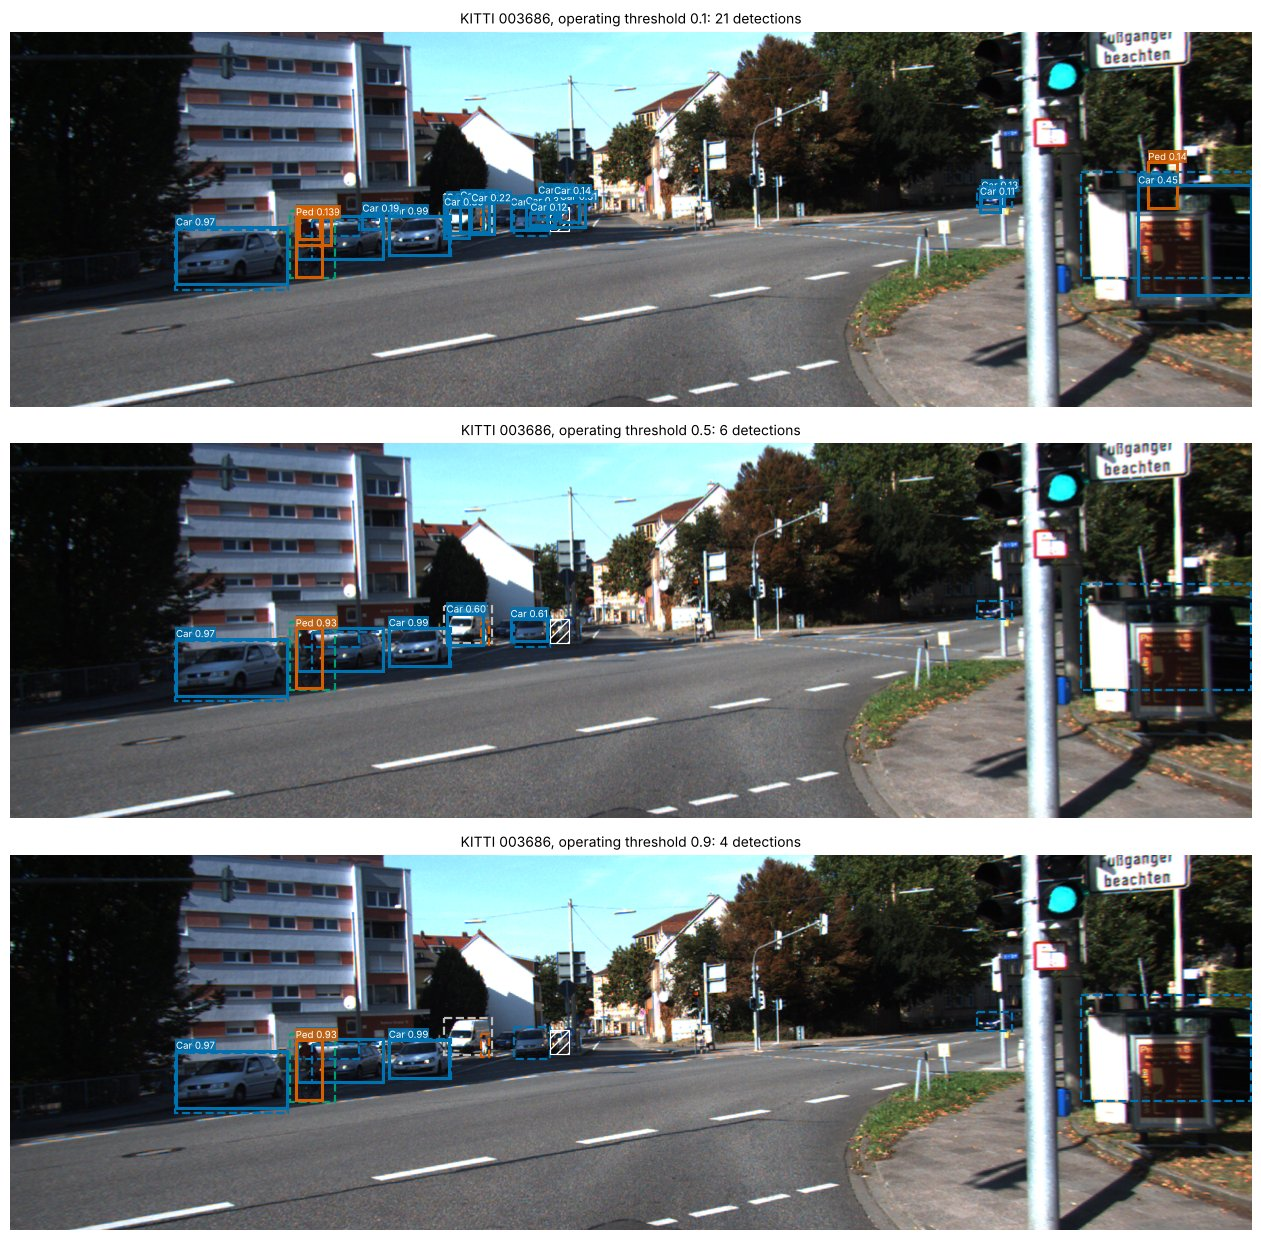

  score >= 0.05: 1084 detections (Car 635, Pedestrian 399, Cyclist 50)
  score >= 0.1 :  712 detections (Car 407, Pedestrian 257, Cyclist 48)
  score >= 0.25:  373 detections (Car 225, Pedestrian 120, Cyclist 28)
  score >= 0.5 :  211 detections (Car 131, Pedestrian 67, Cyclist 13)
  score >= 0.75:  137 detections (Car 88, Pedestrian 40, Cyclist 9)
  score >= 0.9 :  101 detections (Car 67, Pedestrian 28, Cyclist 6)


In [9]:
thresholds = [0.05, 0.1, 0.25, 0.5, 0.75, 0.9]
rows = []
for t in thresholds:
    k = [d for idx in FRAMES for d in dets[idx] if d['score'] >= t]
    rows.append({'threshold': t, 'detections': len(k), **{c: sum(d['cls'] == c for d in k) for c in CLS_COL}})
thr_df = pd.DataFrame(rows); display(thr_df)
n_gt = {c: sum(l['type'] == c for idx in FRAMES for l in frames[idx].labels) for c in CLS_COL}
print(f"Labelled objects in these frames: {n_gt}")

THR_FRAME = FRAMES[20]
fig, axes = plt.subplots(3, 1, figsize=(14, 12.5))
for ax, t in zip(axes, [0.1, 0.5, 0.9]):
    draw_frame(ax, THR_FRAME, t, f"KITTI {THR_FRAME:06d}, operating threshold {t}: "
                                 f"{sum(d['score'] >= t for d in dets[THR_FRAME])} detections")
plt.tight_layout(); plt.show()
for r in rows:
    print(f"  score >= {r['threshold']:<4}: {r['detections']:4d} detections (Car {r['Car']}, Pedestrian {r['Pedestrian']}, Cyclist {r['Cyclist']})")

---
## 6. Precision, recall and Average Precision (AP)

For a set of images with ground truth (GT):

- a detection is a **true positive (TP)** if it matches a not-yet-matched GT object of the same class with IoU ≥ threshold; otherwise a **false positive (FP)**; unmatched GT objects are **false negatives (FN)**;
- $\text{precision} = TP / (TP + FP)$, $\text{recall} = TP / (TP + FN)$.

Sorting all detections by confidence and sweeping the threshold yields the **precision–recall (PR) curve**. **AP** summarises it:

- *PASCAL VOC (2010+)*: all-point interpolation, $AP = \sum_k (r_k - r_{k-1})\,\max_{r \ge r_k} p(r)$;
- *COCO*: interpolated precision averaged at 101 recall points, then over IoU thresholds 0.50:0.05:0.95 → AP@[.5:.95];
- *KITTI (since 2019)*: interpolated precision averaged at **40 recall points** $r \in \{1/40, \dots, 1\}$ (AP|R40, Simonelli et al. 2019; it replaced an 11-point version that rewarded a single high-precision point).

In [10]:
def pr_curve(tp, n_gt):
    tp = np.asarray(tp, bool)
    ctp, cfp = np.cumsum(tp), np.cumsum(~tp)
    return ctp / np.maximum(ctp + cfp, 1), ctp / max(n_gt, 1)          # precision, recall

def ap_all_point(precision, recall):
    # PASCAL VOC 2010+ all-point interpolated AP.
    r = np.concatenate([[0.0], recall, [1.0]]); p = np.concatenate([[0.0], precision, [0.0]])
    p = np.maximum.accumulate(p[::-1])[::-1]                            # precision envelope
    i = np.where(r[1:] != r[:-1])[0]
    return float(np.sum((r[i + 1] - r[i]) * p[i + 1]))

def ap_interp(precision, recall, n_points=40):
    # KITTI AP|R40 (n_points=40) or COCO-style AP (n_points=101, recall grid includes 0).
    grid = np.linspace(1 / n_points, 1, n_points) if n_points == 40 else np.linspace(0, 1, n_points)
    env = np.maximum.accumulate(np.asarray(precision)[::-1])[::-1] if len(precision) else np.asarray(precision)
    return float(np.mean([env[recall >= r].max() if (recall >= r).any() else 0.0 for r in grid]))

# Hand-checked example: 3 GT; detections ranked TP, FP, TP
p_ex, r_ex = pr_curve([True, False, True], 3)
assert np.allclose(r_ex, [1/3, 1/3, 2/3]) and np.allclose(p_ex, [1, 0.5, 2/3])
assert abs(ap_all_point(p_ex, r_ex) - (1/3 * 1 + 1/3 * 2/3)) < 1e-12         # = 0.5556
print(f"Hand example: AP all-point = {ap_all_point(p_ex, r_ex):.4f} (expected 0.5556), "
      f"AP|R40 = {ap_interp(p_ex, r_ex, 40):.4f}, COCO-101 = {ap_interp(p_ex, r_ex, 101):.4f}")

Hand example: AP all-point = 0.5556 (expected 0.5556), AP|R40 = 0.5417, COCO-101 = 0.5545


### KITTI-style matching with ignore rules

The evaluation below follows the KITTI rules in simplified form (greedy matching in descending score order, as in COCO; the official C++ devkit differs in details, so use it for leaderboard numbers):

1. For class *c* and difficulty *L*, a GT object is **valid** if its class is *c* and its difficulty is *L* or easier. GT objects of the neighbouring class (Van for Car, Person_sitting for Pedestrian) or of class *c* but harder than *L* are **ignored**.
2. A detection that matches a valid GT (IoU ≥ 0.7 for Car, 0.5 otherwise) is a TP. One that matches only an ignored GT, lies at least 50 % inside a DontCare region, or is smaller than the level's minimum height (40 / 25 / 25 px) is **ignored**. Anything else is an FP.
3. AP|R40 is computed over all frames together.

In [11]:
IOU_THR = {'Car': 0.7, 'Pedestrian': 0.5, 'Cyclist': 0.5}
NEIGHBOUR = {'Car': 'Van', 'Pedestrian': 'Person_sitting', 'Cyclist': None}
LEVELS = ['Easy', 'Moderate', 'Hard']
RANK = {'Easy': 0, 'Moderate': 1, 'Hard': 2, 'Ignored': 3}
MIN_H = {'Easy': 40, 'Moderate': 25, 'Hard': 25}

def match_frame(frame_dets, labels, cls, level, iou_thr):
    # Returns detection rows (score, status) and the valid GT objects with the score of the detection matching them.
    gt = [l for l in labels if l['type'] in (cls, NEIGHBOUR[cls])]
    gbox = np.array([[l['x1'], l['y1'], l['x2'], l['y2']] for l in gt]).reshape(-1, 4)
    valid = np.array([l['type'] == cls and RANK[l['difficulty']] <= RANK[level] for l in gt], bool)
    dc = np.array([[l['x1'], l['y1'], l['x2'], l['y2']] for l in labels if l['type'] == 'DontCare']).reshape(-1, 4)
    cand_dets = sorted((d for d in frame_dets if d['cls'] == cls), key=lambda d: -d['score'])
    ov = iou_matrix([d['box'] for d in cand_dets], gbox)
    taken, rows, hit = np.zeros(len(gt), bool), [], {}
    for k, d in enumerate(cand_dets):
        status = 'FP'
        for want_valid, label in ((True, 'TP'), (False, 'ignored: neighbour or harder GT')):
            js = np.where(~taken & (valid == want_valid) & (ov[k] >= iou_thr))[0] if len(gt) else []
            if len(js):
                j = js[np.argmax(ov[k][js])]; taken[j] = True; status = label
                if label == 'TP': hit[j] = d['score']
                break
        if status == 'FP' and len(dc):
            b = d['box']
            inter = (np.clip(np.minimum(b[2], dc[:, 2]) - np.maximum(b[0], dc[:, 0]), 0, None) *
                     np.clip(np.minimum(b[3], dc[:, 3]) - np.maximum(b[1], dc[:, 1]), 0, None))
            if (inter / max((b[2] - b[0]) * (b[3] - b[1]), 1e-6)).max() >= 0.5:
                status = 'ignored: DontCare'
        if status == 'FP' and d['box'][3] - d['box'][1] < MIN_H[level]:
            status = 'ignored: below min. height'
        rows.append({'score': d['score'], 'status': status, 'box': d['box']})
    gts = [{'label': gt[j], 'hit_score': hit.get(j)} for j in np.where(valid)[0]]
    return rows, gts

def evaluate(cls, level, frame_ids=FRAMES):
    det_rows, gt_rows = [], []
    for idx in frame_ids:
        r, g = match_frame(dets[idx], frames[idx].labels, cls, level, IOU_THR[cls])
        det_rows += [dict(x, frame=idx) for x in r]; gt_rows += [dict(x, frame=idx) for x in g]
    scored = sorted((x for x in det_rows if x['status'] in ('TP', 'FP')), key=lambda x: -x['score'])
    prec, rec = pr_curve([x['status'] == 'TP' for x in scored], len(gt_rows))
    return {'ap40': ap_interp(prec, rec, 40) if gt_rows else np.nan, 'prec': prec, 'rec': rec,
            'scores': np.array([x['score'] for x in scored]), 'n_gt': len(gt_rows), 'dets': det_rows, 'gts': gt_rows}

results = {(c, L): evaluate(c, L) for c in CLS_COL for L in LEVELS}
ap_tab = pd.DataFrame({L: {c: results[(c, L)]['ap40'] for c in CLS_COL} for L in LEVELS})
n_tab = pd.DataFrame({L: {c: results[(c, L)]['n_gt'] for c in CLS_COL} for L in LEVELS})
print("AP|R40 (KITTI 2D, IoU 0.7 / 0.5 / 0.5) on the selected frames:")
display(ap_tab.round(3))
print("Valid ground-truth objects per cell (cumulative levels):")
display(n_tab)
for c in CLS_COL:
    print(f"  {c:10s}: Easy {ap_tab.loc[c, 'Easy']:.3f} | Moderate {ap_tab.loc[c, 'Moderate']:.3f} | "
          f"Hard {ap_tab.loc[c, 'Hard']:.3f}  (Moderate n = {n_tab.loc[c, 'Moderate']})")

AP|R40 (KITTI 2D, IoU 0.7 / 0.5 / 0.5) on the selected frames:


,Easy,Moderate,Hard
Car,0.835,0.723,0.661
Pedestrian,0.731,0.563,0.513
Cyclist,0.356,0.331,0.347


Valid ground-truth objects per cell (cumulative levels):


,Easy,Moderate,Hard
Car,33,81,95
Pedestrian,34,58,65
Cyclist,13,22,24


  Car       : Easy 0.835 | Moderate 0.723 | Hard 0.661  (Moderate n = 81)
  Pedestrian: Easy 0.731 | Moderate 0.563 | Hard 0.513  (Moderate n = 58)
  Cyclist   : Easy 0.356 | Moderate 0.331 | Hard 0.347  (Moderate n = 22)


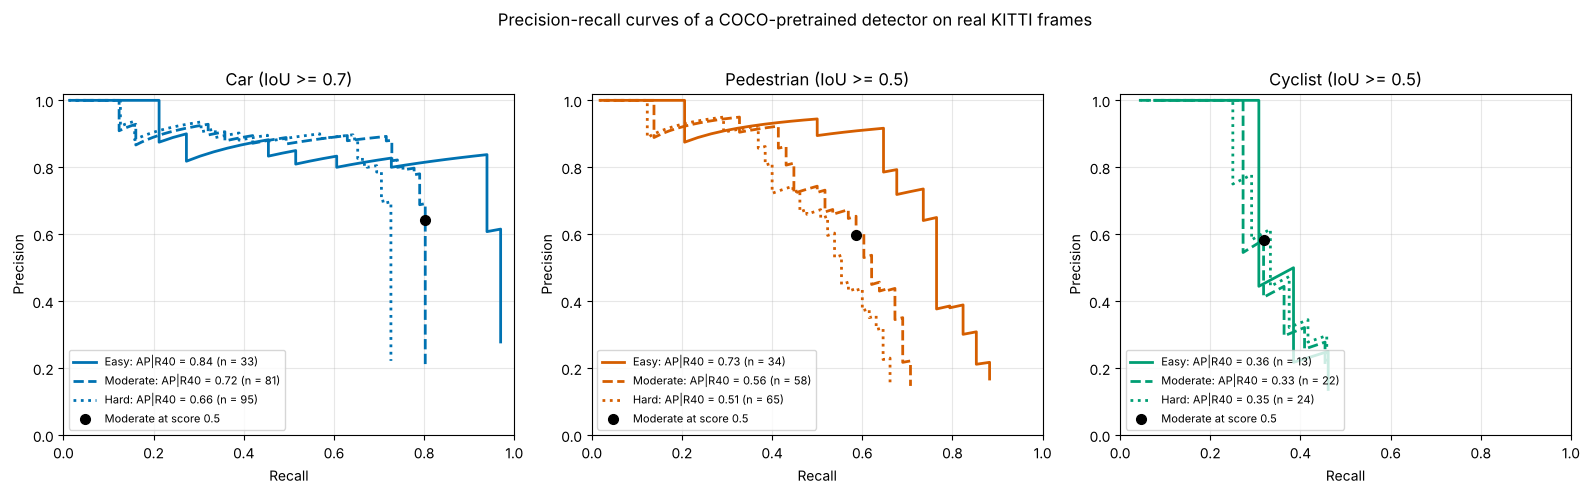

  Car        Moderate: maximum recall at any threshold 0.80 -> 16 of 81 objects are never found
  Pedestrian Moderate: maximum recall at any threshold 0.71 -> 17 of 58 objects are never found
  Cyclist    Moderate: maximum recall at any threshold 0.45 -> 12 of 22 objects are never found


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, c in zip(axes, CLS_COL):
    for L, ls in zip(LEVELS, ['-', '--', ':']):
        r = results[(c, L)]
        ax.plot(r['rec'], r['prec'], ls=ls, color=CLS_COL[c], lw=2, label=f"{L}: AP|R40 = {r['ap40']:.2f} (n = {r['n_gt']})")
    r = results[(c, 'Moderate')]
    if len(r['scores']):
        k = np.searchsorted(-r['scores'], -OP_THR, side='right') - 1
        if k >= 0:
            ax.plot(r['rec'][k], r['prec'][k], 'ko', ms=7, label=f"Moderate at score {OP_THR}")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02); ax.grid(alpha=0.3)
    ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title(f"{c} (IoU >= {IOU_THR[c]})"); ax.legend(fontsize=8, loc='lower left')
plt.suptitle('Precision-recall curves of a COCO-pretrained detector on real KITTI frames', y=1.02)
plt.tight_layout(); plt.show()
for c in CLS_COL:
    r = results[(c, 'Moderate')]
    print(f"  {c:10s} Moderate: maximum recall at any threshold {r['rec'].max() if len(r['rec']) else 0:.2f} "
          f"-> {r['n_gt'] - int(round((r['rec'].max() if len(r['rec']) else 0) * r['n_gt']))} of {r['n_gt']} objects are never found")

### How certain are these numbers?

With a few dozen objects per class, AP has a large sampling error. A **bootstrap over frames** (resample the 36 frames with replacement, recompute AP) gives an interval. Frames, not objects, are resampled because objects in one frame share conditions.

In [13]:
B = 300
boot = {c: [] for c in CLS_COL}
brng = np.random.default_rng(7)
for _ in range(B):
    sample = list(brng.choice(FRAMES, len(FRAMES), replace=True))
    for c in CLS_COL:
        boot[c].append(evaluate(c, 'Moderate', sample)['ap40'])
ci = pd.DataFrame({c: {'AP|R40 Moderate': results[(c, 'Moderate')]['ap40'], 'n GT': results[(c, 'Moderate')]['n_gt'],
                       '95 % CI low': np.nanpercentile(boot[c], 2.5), '95 % CI high': np.nanpercentile(boot[c], 97.5)}
                   for c in CLS_COL}).T
display(ci.round(3))
for c, r in ci.iterrows():
    print(f"  {c:10s}: AP {r['AP|R40 Moderate']:.2f}, 95 % bootstrap interval [{r['95 % CI low']:.2f}, {r['95 % CI high']:.2f}] "
          f"from {int(r['n GT'])} objects (width {r['95 % CI high'] - r['95 % CI low']:.2f})")
print("A KPI quoted without its sample size and interval cannot be compared with a target.")

,AP|R40 Moderate,n GT,95 % CI low,95 % CI high
Car,0.723,81.0,0.611,0.836
Pedestrian,0.563,58.0,0.373,0.672
Cyclist,0.331,22.0,0.075,0.556


  Car       : AP 0.72, 95 % bootstrap interval [0.61, 0.84] from 81 objects (width 0.23)
  Pedestrian: AP 0.56, 95 % bootstrap interval [0.37, 0.67] from 58 objects (width 0.30)
  Cyclist   : AP 0.33, 95 % bootstrap interval [0.07, 0.56] from 22 objects (width 0.48)
A KPI quoted without its sample size and interval cannot be compared with a target.


### Recall by object size

COCO groups objects by area (small < 32² px²); KITTI by height. The physically meaningful variable for driving is distance, which for a given object class is roughly inverse to box height.

mean                    size                   
class        Car Cyclist Pedestrian  Car Cyclist Pedestrian
height bin                                                 
25-40       0.61    0.00       0.50   31       2          4
40-60       0.53    0.17       0.38   30       6          8
60-100      1.00    0.10       0.48   21      10         21
>100        1.00    1.00       0.59   13       6         32

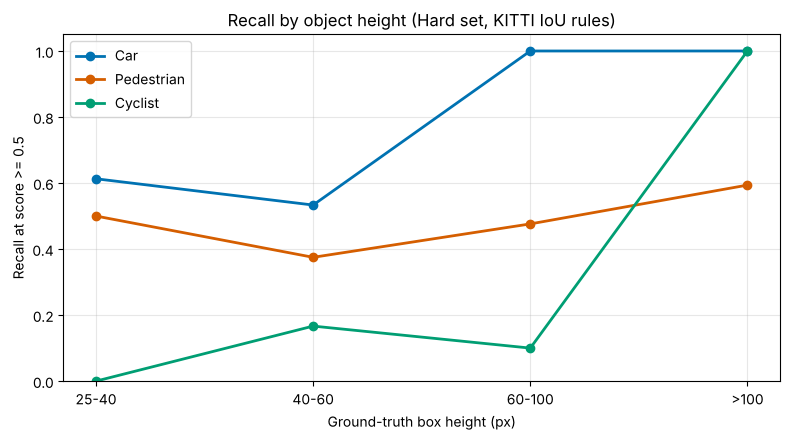

Recall for objects < 40 px high: 0.57; for objects >= 100 px: 0.75 (all classes, score >= 0.5).


In [14]:
recs = []
for c in CLS_COL:
    for g in results[(c, 'Hard')]['gts']:
        l = g['label']
        recs.append({'class': c, 'height_px': l['y2'] - l['y1'], 'distance_m': np.hypot(l['x'], l['z']),
                     'occluded': l['occluded'], 'found': g['hit_score'] is not None and g['hit_score'] >= OP_THR})
gt_df = pd.DataFrame(recs)
gt_df['height bin'] = pd.cut(gt_df['height_px'], [25, 40, 60, 100, 400], labels=['25-40', '40-60', '60-100', '>100'])
rec_tab = gt_df.pivot_table(index='height bin', columns='class', values='found', aggfunc=['mean', 'size'], observed=False)
display(rec_tab.round(2))
fig, ax = plt.subplots(figsize=(8, 4.5))
for c in CLS_COL:
    s = gt_df[gt_df['class'] == c].groupby('height bin', observed=False)['found'].mean()
    ax.plot(range(len(s)), s.values, 'o-', color=CLS_COL[c], lw=2, label=c)
ax.set_xticks(range(4)); ax.set_xticklabels(['25-40', '40-60', '60-100', '>100'])
ax.set_xlabel('Ground-truth box height (px)'); ax.set_ylabel(f'Recall at score >= {OP_THR}')
ax.set_ylim(0, 1.05); ax.grid(alpha=0.3); ax.legend(); ax.set_title('Recall by object height (Hard set, KITTI IoU rules)')
plt.tight_layout(); plt.show()
small, large = gt_df[gt_df['height_px'] < 40]['found'].mean(), gt_df[gt_df['height_px'] >= 100]['found'].mean()
print(f"Recall for objects < 40 px high: {small:.2f}; for objects >= 100 px: {large:.2f} (all classes, score >= {OP_THR}).")

---
## 7. Failure cases on real images

The gallery shows the **missed** ground-truth objects (Moderate set, no matching detection at score ≥ 0.5) and the highest-scoring **false positives**. Each crop is labelled with the information an engineer needs to classify the failure.

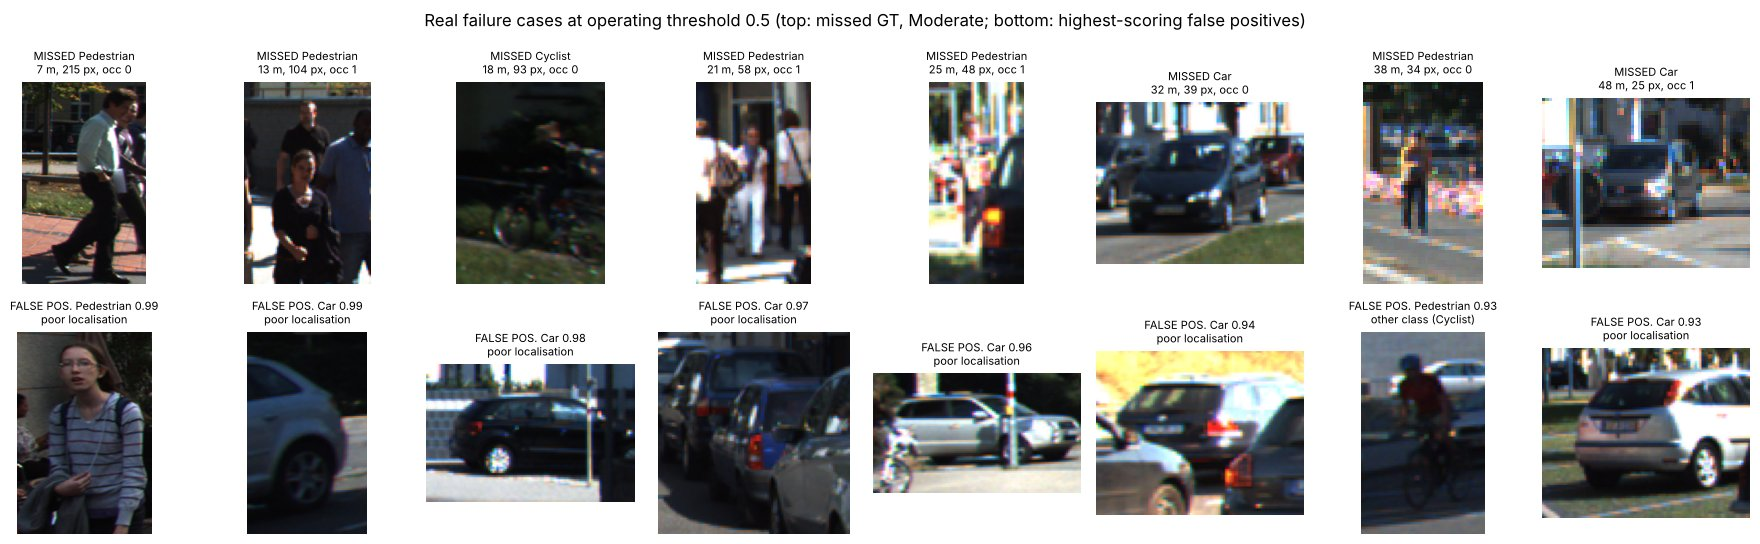

Missed at score >= 0.5: 55 of 161 Moderate objects; false positives: 64.
Missed objects by class: {'Pedestrian': 24, 'Car': 16, 'Cyclist': 15}
  24 % of misses are < 40 px high; 53 % are partly or largely occluded; 2 % are truncated by > 15 %.
  10 misses had a matching box with a score below 0.5 (a threshold problem); the rest had no matching box at all (a model problem).
False positives by kind: {'poor localisation': 44, 'no overlapping label': 13, 'other class (Cyclist)': 5, 'other class (Pedestrian)': 2}


In [15]:
def crop(idx, box, pad=12):
    im = frames[idx].image; h, w = im.shape[:2]
    x1, y1, x2, y2 = [int(round(v)) for v in box]
    return im[max(0, y1 - pad):min(h, y2 + pad), max(0, x1 - pad):min(w, x2 + pad)]

missed, fps = [], []
for c in CLS_COL:
    r = results[(c, 'Moderate')]
    for g in r['gts']:
        if g['hit_score'] is None or g['hit_score'] < OP_THR:
            l = g['label']
            missed.append({'class': c, 'frame': g['frame'], 'box': [l['x1'], l['y1'], l['x2'], l['y2']],
                           'height_px': l['y2'] - l['y1'], 'occluded': l['occluded'], 'truncated': l['truncated'],
                           'distance_m': np.hypot(l['x'], l['z']), 'best_score': g['hit_score']})
    fps += [dict(d, cls=c) for d in r['dets'] if d['status'] == 'FP' and d['score'] >= OP_THR]
missed_df = pd.DataFrame(missed); fps = sorted(fps, key=lambda d: -d['score'])

def fp_kind(f):
    # Classify a false positive by its best overlap with any (non-DontCare) label of the frame.
    labs = [l for l in frames[f['frame']].labels if l['type'] != 'DontCare']
    ov = iou_matrix([f['box']], [[l['x1'], l['y1'], l['x2'], l['y2']] for l in labs])[0] if labs else np.zeros(0)
    same = [o for o, l in zip(ov, labs) if l['type'] in (f['cls'], NEIGHBOUR[f['cls']])]
    other = [(o, l['type']) for o, l in zip(ov, labs) if l['type'] not in (f['cls'], NEIGHBOUR[f['cls']])]
    if same and max(same) >= IOU_THR[f['cls']]:
        return 'duplicate'
    if same and max(same) >= 0.1:
        return 'poor localisation'
    if other and max(other)[0] >= 0.3:
        return f"other class ({max(other)[1]})"
    return 'no overlapping label'

for f in fps:
    f['kind'] = fp_kind(f)
n_show = 8
fig, axes = plt.subplots(2, n_show, figsize=(18, 5.5))
for ax, m_ in zip(axes[0], missed_df.sort_values('distance_m').iloc[np.linspace(0, len(missed_df) - 1, n_show).astype(int)].to_dict('records')):
    ax.imshow(crop(m_['frame'], m_['box'])); ax.axis('off')
    ax.set_title(f"MISSED {m_['class']}\n{m_['distance_m']:.0f} m, {m_['height_px']:.0f} px, occ {m_['occluded']}", fontsize=8)
for ax, f_ in zip(axes[1], fps[:n_show]):
    ax.imshow(crop(f_['frame'], f_['box'])); ax.axis('off')
    ax.set_title(f"FALSE POS. {f_['cls']} {f_['score']:.2f}\n{f_['kind']}", fontsize=8)
for ax in list(axes[0][len(missed_df):]) + list(axes[1][len(fps):]):
    ax.axis('off')
plt.suptitle(f'Real failure cases at operating threshold {OP_THR} (top: missed GT, Moderate; bottom: highest-scoring false positives)')
plt.tight_layout(); plt.show()

n_valid = sum(results[(c, 'Moderate')]['n_gt'] for c in CLS_COL)
print(f"Missed at score >= {OP_THR}: {len(missed_df)} of {n_valid} Moderate objects; false positives: {len(fps)}.")
if len(missed_df):
    print("Missed objects by class:", missed_df['class'].value_counts().to_dict())
    print(f"  {100 * (missed_df['height_px'] < 40).mean():.0f} % of misses are < 40 px high; "
          f"{100 * (missed_df['occluded'] >= 1).mean():.0f} % are partly or largely occluded; "
          f"{100 * (missed_df['truncated'] > 0.15).mean():.0f} % are truncated by > 15 %.")
    print(f"  {int(missed_df['best_score'].notna().sum())} misses had a matching box with a score below {OP_THR} "
          "(a threshold problem); the rest had no matching box at all (a model problem).")
print("False positives by kind:", pd.Series([f['kind'] for f in fps]).value_counts().to_dict())

**Discussion.** What the real failures show (compare with the printed statistics):

- **Occlusion and crowds** cause many of the misses. In a group of pedestrians the detector draws a box around the *visible* part of a partly hidden person, while the label covers the whole person, so the IoU falls below 0.5; or NMS removes the box of a person standing directly behind another.
- **Small and distant objects** are the other large group: at 25–40 px a pedestrian is a handful of pixels wide, and the COCO model, trained on photographs in which people are usually large, has little evidence.
- **Cyclists** suffer from the ontology mismatch: rider and bicycle must both be found and merged, and a rider in shadow is easily lost.
- **False positives** are rarely hallucinations. Most are *real* objects scored as errors: boxes that are poorly localised (a car box with IoU 0.5–0.7 counts as a false positive for Car), duplicates, objects of a different KITTI class, or people and cars at the image border whose labelled box is truncated differently. For a safety analysis each false positive must be classified, because only some of them would reach the brake.

These are exactly the *performance insufficiencies* and *triggering conditions* that ISO 21448 asks to identify and evaluate (see [04_SOTIF_ISO21448/02](../04_SOTIF_ISO21448/02_triggering_conditions_and_scenarios.ipynb)). Note also what the sample does not contain: KITTI has no night, rain or fog, so none of those triggering conditions can appear here.

---
## 8. Throughput and latency

- **Throughput (FPS)**: how many frames per second the detector processes (can be raised by batching or pipelining).
- **Latency**: the time from capture to output for one frame; the end-to-end perception → actuation budget is of the order of 100 ms. **FPS ≠ latency.**

The cell below measures single-frame CPU latency of this model on five frames (warm model, no download).

In [16]:
m = get_model()
lat = []
with torch.no_grad():
    for idx in FRAMES[:6]:
        x = torch.from_numpy(frames[idx].image.copy()).permute(2, 0, 1).float() / 255
        t0 = time.perf_counter(); m([x]); lat.append(1000 * (time.perf_counter() - t0))
lat = np.array(lat[1:])                                       # first call includes warm-up
print(f"{MODEL_NAME} on CPU (CPU threads: {torch.get_num_threads()}): median {np.median(lat):.0f} ms per frame, "
      f"max {lat.max():.0f} ms (n = {len(lat)}); hardware- and load-dependent.")
print(f"-> {'keeps up with' if np.median(lat) < 100 else 'does NOT keep up with'} a 10 Hz camera (KITTI) on this machine.")
for v in (30, 50, 100, 130):
    print(f"  {v:3d} km/h: {v / 3.6 * np.median(lat) / 1000:4.1f} m travelled during one inference")

try:                                                           # optional: Ultralytics YOLO (installed on Colab only)
    from ultralytics import YOLO
    yolo = YOLO('yolo11n.pt')
    bgr = np.ascontiguousarray(frames[FRAMES[0]].image[..., ::-1]); yolo.predict(bgr, verbose=False)
    t0 = time.perf_counter(); r = yolo.predict(bgr, verbose=False)[0]
    print(f"Optional YOLO11n: {1000 * (time.perf_counter() - t0):.0f} ms, {len(r.boxes)} boxes on the same frame.")
except Exception as exc:
    print(f"Optional YOLO comparison skipped ({type(exc).__name__}); on Colab: pip install ultralytics.")

fasterrcnn_mobilenet_v3_large_fpn on CPU (CPU threads: 1): median 2032 ms per frame, max 2285 ms (n = 5); hardware- and load-dependent.
-> does NOT keep up with a 10 Hz camera (KITTI) on this machine.
   30 km/h: 16.9 m travelled during one inference
   50 km/h: 28.2 m travelled during one inference
  100 km/h: 56.4 m travelled during one inference
  130 km/h: 73.4 m travelled during one inference
Optional YOLO comparison skipped (ModuleNotFoundError); on Colab: pip install ultralytics.


**Why AP is not a safety metric on its own:** it averages over confidence thresholds, and (as mAP) over classes; it treats a missed pedestrian at 10 m like a missed car at 60 m. Safety arguments need **targeted** metrics: recall for safety-relevant classes, per distance band and per condition, at the *chosen operating threshold*, with a confidence interval — see [05 Vulnerable road user detection](05_vulnerable_road_user_detection.ipynb).

---
## Exercise: probe the evaluation

1. Change `OP_THR` to 0.3 and to 0.7 and re-run Sections 6–7. How do the number of misses and false positives change?
2. Evaluate Car with IoU 0.5 instead of 0.7 (`IOU_THR['Car'] = 0.5`). How much of the Car AP was lost to localisation rather than to missed cars?
3. Remove the cyclist merge (treat every `person` as Pedestrian). What happens to Pedestrian precision and Cyclist recall?

In [17]:
# Example for question 2 (uncomment):
# IOU_THR['Car'] = 0.5; print(f"Car Moderate AP|R40 at IoU 0.5: {evaluate('Car', 'Moderate')['ap40']:.3f}"); IOU_THR['Car'] = 0.7
print(f"Car Moderate AP|R40 at IoU 0.7: {results[('Car', 'Moderate')]['ap40']:.3f}")

Car Moderate AP|R40 at IoU 0.7: 0.723


---
## Safety perspective

- A detector's **confidence is not a calibrated probability**: a score of 0.9 does not mean a 90 % chance of being correct. Calibration is measured and corrected in [06_AI_Safety_ISO_PAS_8800/04 — Calibration](../06_AI_Safety_ISO_PAS_8800/04_calibration.ipynb).
- Missed or poorly localised objects caused by model limitations — small objects, occlusion, crowds suppressed by NMS, classes the model was never trained on — are **performance insufficiencies** (ISO 21448:2022). When they originate in the ML model or its training data, ISO/PAS 8800:2024 asks for AI-specific data, training and verification measures.
- The **class mapping, ignore rules, IoU thresholds, operating threshold and NMS settings** are part of the safety-relevant specification: two teams can report very different AP on the same detector by choosing them differently.
- Both errors matter: a missed pedestrian can cause a collision (in the course's AEB example: SG-02, ASIL B); a phantom object can cause unintended braking (SG-01, ASIL D).

Continue with: [05 Vulnerable road user detection](05_vulnerable_road_user_detection.ipynb) · [02_Failures_and_Robustness/03 — OOD detection](../02_Failures_and_Robustness/03_out_of_distribution_detection.ipynb) · [04_SOTIF_ISO21448/01 — SOTIF fundamentals](../04_SOTIF_ISO21448/01_sotif_fundamentals.ipynb).

---
## In industry

**Work product:** the *perception KPI specification* and the *perception verification report*, which feed the SOTIF evaluation of known hazardous scenarios (ISO 21448, Clause 9 V&V strategy and Clause 10 evaluation of known scenarios) and the AI component's verification evidence (ISO/PAS 8800).

**Who:** the perception V&V engineer defines and computes the KPIs; the SOTIF/safety engineer derives the targets from the hazard analysis and the acceptance criteria; the assessor checks that the metric measures what the argument claims.

A KPI is only usable as evidence if every term is fixed. Example (illustrative values):

| Field | Example |
|---|---|
| KPI ID | PER-KPI-03 |
| Metric | Recall of Pedestrian, per frame, at the released operating threshold |
| Population | Pedestrians with box height ≥ 25 px, occlusion ≤ 1, truncation ≤ 0.3, distance 5–40 m, ODD subset "urban, daylight, dry" |
| Matching | IoU ≥ 0.5, one-to-one, greedy by score; Person_sitting ignored; DontCare policy v2.1 |
| Data | Test set TS-URB-07 (independent drives, 2,000 pedestrian tracks), frozen hash |
| Target | ≥ 0.97 with a one-sided 95 % lower confidence bound ≥ 0.95 |
| Traceability | Derived from SG-02 / AEB detection-range requirement; referenced in the SOTIF validation plan |

**What reviewers and assessors look for**

- [ ] The KPI fixes threshold, IoU, class mapping, ignore rules and population — not just "mAP"
- [ ] Results are disaggregated by class, distance, occlusion and condition, with sample sizes and intervals
- [ ] The test data is independent of the training data (by drive or location) and frozen
- [ ] Failure cases are reviewed and classified (threshold vs model vs label error) and fed into the triggering-condition list
- [ ] False positives are reported per hour or per kilometre, because they drive unintended braking
- [ ] Pretrained weights and datasets have documented provenance and licences

## Key takeaways

- A 2D detector outputs boxes, classes and scores; scores are rankings, not probabilities.
- Evaluating a COCO model on KITTI requires a class mapping; Van/Car, Person_sitting/Pedestrian, rider/Cyclist and DontCare all change the result and must be specified.
- KITTI evaluates per class with IoU 0.7 (Car) and 0.5 (Pedestrian, Cyclist), on Easy/Moderate/Hard levels defined by box height, occlusion and truncation, using AP|R40.
- IoU, NMS and AP implemented from scratch agree with torchvision's reference implementations.
- On real KITTI frames the COCO-pretrained MobileNet detector is strong on large, visible cars and weaker on occluded, crowded, small and truncated objects and on cyclists; most "false positives" are real objects that are poorly localised, duplicated or of another class.
- With a few dozen objects per class the bootstrap interval of AP is wide: report sample sizes and intervals with every KPI.
- Real overlapping pedestrians exist in KITTI: NMS settings are safety-relevant.
- Threshold, IoU, mapping and ignore rules belong in the KPI specification that feeds the SOTIF argument.

## Self-assessment

1. What three outputs does an object detector provide for each object, and what are the two common box formats?
2. Compute the IoU of boxes [0, 0, 10, 10] and [5, 5, 15, 15].
3. Why does KITTI use IoU 0.7 for cars but 0.5 for pedestrians?
4. A COCO model detects a cyclist's rider as `person`. How is this scored for the KITTI Pedestrian class if no merge is applied, and why?
5. What is the purpose of DontCare regions in evaluation, and what goes wrong if they are ignored?
6. Your detector reaches Pedestrian AP|R40 = 0.62 on 60 objects. What else do you need to state before comparing it with a target of 0.70?
7. Explain how NMS can cause a false negative in a crowded scene, and one way to mitigate it.

<details>
<summary>Show answers</summary>

1. Bounding box, class label and confidence score. Corner format [x1, y1, x2, y2] and COCO format [x, y, w, h].
2. Intersection 5 × 5 = 25; union 100 + 100 − 25 = 175; IoU = 25/175 ≈ 0.143.
3. Cars are large and rigid, so tight localisation is achievable and needed for 3D estimation; pedestrians are small and deformable, and a few pixels of error already cost a lot of IoU (Section 3).
4. As a false positive: KITTI labels the rider and bicycle together as Cyclist, which is not a neighbouring class of Pedestrian, so the `person` box matches nothing valid or ignored for Pedestrian.
5. They mark unlabelled objects (distant cars, crowds). Without them, every correct detection of such an object would be counted as a false positive and precision would be underestimated.
6. The difficulty level and population, IoU threshold, class mapping and ignore rules, and the uncertainty: with 60 objects the bootstrap interval is easily ±0.1 or wider, so 0.62 may not be distinguishable from 0.70.
7. Two people close together produce boxes with IoU above the NMS threshold, so the lower-scoring person is suppressed. Mitigations: a higher or class-specific NMS threshold for persons, Soft-NMS, NMS-free detectors, or confirmation from LiDAR/radar.

</details>

## References

1. Geiger, A., Lenz, P., Urtasun, R. (2012). Are we ready for autonomous driving? The KITTI vision benchmark suite. *CVPR*. https://doi.org/10.1109/CVPR.2012.6248074
2. Ren, S., He, K., Girshick, R., Sun, J. (2017). Faster R-CNN: Towards real-time object detection with region proposal networks. *IEEE TPAMI* 39(6). https://doi.org/10.1109/TPAMI.2016.2577031
3. Howard, A. et al. (2019). Searching for MobileNetV3. *ICCV*. https://doi.org/10.1109/ICCV.2019.00140
4. Lin, T.-Y. et al. (2017). Feature pyramid networks for object detection. *CVPR*. https://doi.org/10.1109/CVPR.2017.106
5. Lin, T.-Y. et al. (2014). Microsoft COCO: Common objects in context. *ECCV*. https://doi.org/10.1007/978-3-319-10602-1_48
6. Everingham, M. et al. (2010). The PASCAL Visual Object Classes (VOC) challenge. *IJCV* 88, 303–338. https://doi.org/10.1007/s11263-009-0275-4
7. Simonelli, A. et al. (2019). Disentangling monocular 3D object detection. *ICCV* (introduces AP|R40, adopted by KITTI). https://doi.org/10.1109/ICCV.2019.00208
8. Redmon, J. et al. (2016). You only look once: Unified, real-time object detection. *CVPR*. arXiv:1506.02640
9. Carion, N. et al. (2020). End-to-end object detection with transformers (DETR). *ECCV*. arXiv:2005.12872
10. Zhao, Y. et al. (2024). DETRs beat YOLOs on real-time object detection (RT-DETR). *CVPR*. arXiv:2304.08069
11. Ultralytics (2026). YOLO26 vs YOLO11 comparison. https://docs.ultralytics.com/compare/yolo26-vs-yolo11
12. ISO 21448:2022. *Road vehicles — Safety of the intended functionality.* https://www.iso.org/standard/77490.html
13. ISO/PAS 8800:2024. *Road vehicles — Safety and artificial intelligence.* https://www.iso.org/standard/83303.html
14. Patel, M., Jung, R. (2026). Uncertainty evaluation to support safety of the intended functionality analysis for identifying performance insufficiencies in ML-based LiDAR object detection. *VEHITS 2026*. https://doi.org/10.5220/0014967200004030

### Further practice

Companion hands-on material: [AI Perception Safety Workshop — Notebook 02, Object detection basics](https://github.com/milinpatel07/AI-Perception-Safety-Workshop/blob/main/notebooks/02_object_detection_basics.ipynb).

---
**Navigation:** ← [03 LiDAR and point clouds](03_lidar_point_clouds.ipynb) · [Module index](README.md) · [05 Vulnerable road user detection](05_vulnerable_road_user_detection.ipynb) →